In [1]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:41592")
client

<Client: 'tcp://127.0.0.1:41592' processes=8 threads=32, memory=503.70 GiB>

In [2]:
import numpy as np
import xarray as xr
import os.path as op

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

In [4]:
for pp in range(6,7):
    ds = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                        ).chunk({"time":10,"y":400,"x":400})
    
    ke = .5*(ds["u.x"]**2 + ds["u.y"]**2).where(ds.h > 0.)
    hke = ds.h * ke

    Hke = (hke.sum("level", skipna=True) 
           / ds.h.sum("level", skipna=True))
    dsave = Hke.to_dataset(name="ke")
    dsave.to_zarr(op.join(ddir,"SW/KE/VertAve_p%02d.zarr" % pp),
                  mode="w")
    dsave.close()
    ds.close()

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


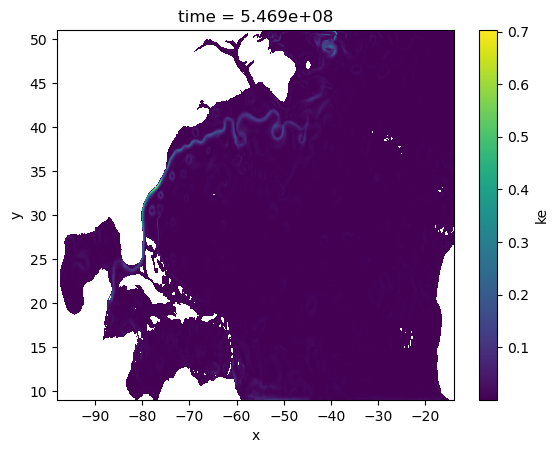

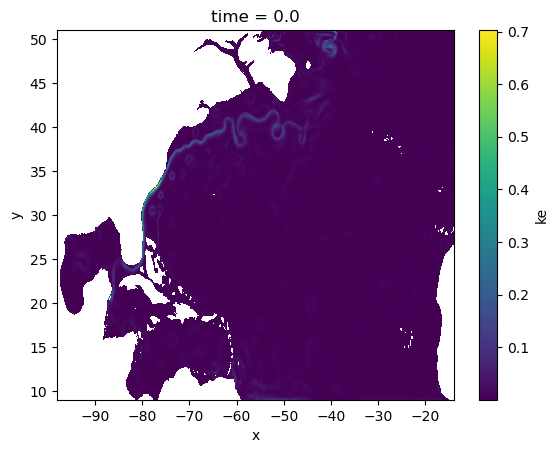

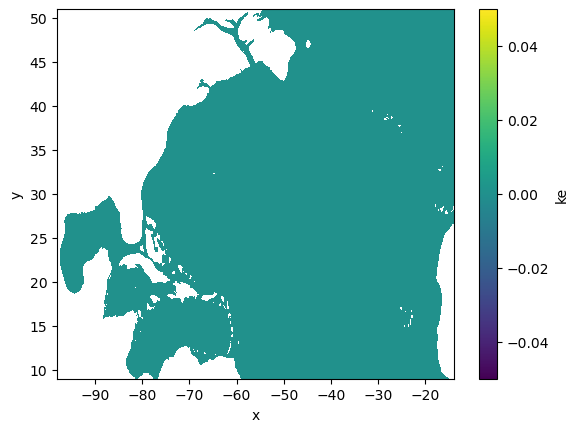

In [5]:
ds = xr.open_zarr(op.join(ddir,"SW/KE/VertAve_p%02d.zarr" % 6))
ke6 = ds.ke
ke6.isel(time=-1).plot(rasterized=True)
plt.show()
ds = xr.open_zarr(op.join(ddir,"SW/KE/VertAve_p%02d.zarr" % 7))
ke7 = ds.ke
ke7.isel(time=0).plot(rasterized=True)
plt.show()
(ke7.isel(time=0)-ke6.isel(time=-1)).plot(rasterized=True)

In [8]:
for pp in range(6,7):
    ds = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                        ).chunk({"time":10,"y":400,"x":400})
    
    h2 = .5*((ds.h.where(ds.h > 0.) 
              - ds.h.where(ds.h > 0.).mean(["y","x"],skipna=True)
             )**2)
    h2 = ds.h * h2

    Hh2 = (h2.sum("level", skipna=True) 
           / ds.h.sum("level", skipna=True))
    dsave = Hh2.to_dataset(name="h2")
    dsave.to_zarr(op.join(ddir,"SW/h2/VertAve_p%02d.zarr" % pp),
                  mode="w")
    dsave.close()
    ds.close()

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


In [6]:
for pp in range(1,9):
    if pp == 1:
        dske = xr.open_zarr(op.join(ddir,"SW/KE/VertAve_p%02d.zarr" 
                                    % pp))
    else:
        # try:
        tmp = xr.open_zarr(op.join(ddir,"SW/KE/VertAve_p%02d.zarr" 
                                   % pp)
                          ).isel(time=slice(1,None))
        time = tmp.time.data + dske.time[-1].data
        tmp = tmp.reset_index("time", drop=False)
        tmp = tmp.reset_coords("time", drop=True)
        tmp.coords["time"] = ("time",time)
        dske = xr.concat([dske, 
                          tmp
                         ], "time")
        # except:
        #     pass
dske

<xarray.Dataset> Size: 54GB
Dimensions:  (time: 1612, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 6kB 0.0 2.592e+06 5.184e+06 ... 4.173e+09 4.176e+09
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    ke       (time, y, x) float32 54GB dask.array<chunksize=(10, 400, 400), meta=np.ndarray>

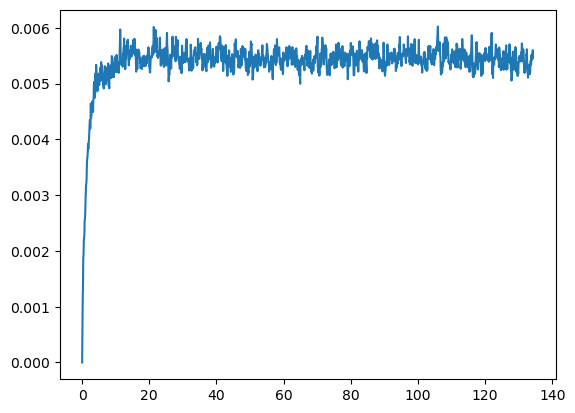

In [13]:
fig, ax = plt.subplots()
ax.plot(dske.time/86400./360.,
        dske.ke.mean(["y","x"], skipna=True)
       )

In [11]:
for pp in range(1,9):
    if pp == 1:
        dsh2 = xr.open_zarr(op.join(ddir,"SW/h2/VertAve_p%02d.zarr" 
                                    % pp))
    else:
        # try:
        tmp = xr.open_zarr(op.join(ddir,"SW/h2/VertAve_p%02d.zarr" 
                                   % pp)
                          ).isel(time=slice(1,None))
        time = tmp.time.data + dsh2.time[-1].data
        tmp = tmp.reset_index("time", drop=False)
        tmp = tmp.reset_coords("time", drop=True)
        tmp.coords["time"] = ("time",time)
        dsh2 = xr.concat([dsh2, 
                          tmp
                         ], "time")
        # except:
        #     pass
dsh2

<xarray.Dataset> Size: 54GB
Dimensions:  (time: 1612, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 6kB 0.0 2.592e+06 5.184e+06 ... 4.173e+09 4.176e+09
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    h2       (time, y, x) float32 54GB dask.array<chunksize=(10, 400, 400), meta=np.ndarray>

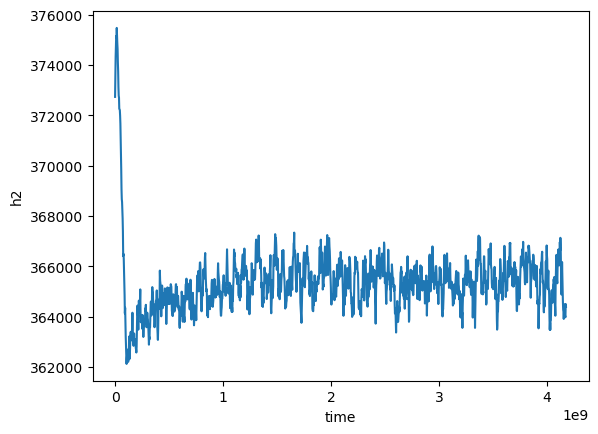

In [12]:
dsh2.h2.mean(["y","x"], skipna=True).plot()